# Quantum Input Encoding Schemes

This Notebook provides a comprehensive guide to various input-encoding schemes used in quantum computing and quantum machine learning. Understanding how to encode classical data into quantum states is fundamental to quantum algorithms and QML models.


1. **Basis Encoding** - Encoding classical bits into computational basis states
2. **Amplitude Encoding** - Encoding data into quantum state amplitudes
3. **Angle Encoding** - Encoding data using rotation angles
4. **Qsample Encoding** - Encoding probability distributions
5. **Hamiltonian Encoding** - Encoding data into Hamiltonian operators
6. **Quantum Feature Maps** - Structured encoding circuits (ZZFeatureMap, PauliFeatureMap, etc.)

Each encoding scheme has different advantages, resource requirements, and use cases. We'll explore them all with theory, code examples, and visualizations.


## 1. Introduction to Quantum Encoding

### Why Encoding Matters

In quantum computing, classical data must be encoded into quantum states before quantum algorithms can process it. The choice of encoding scheme significantly impacts:

- **Circuit depth** (number of gates)
- **Number of qubits** required
- **Expressiveness** of the encoded data
- **Noise sensitivity** on real hardware
- **Computational efficiency**

### Key Considerations

When choosing an encoding scheme, consider:

1. **Data dimensionality**: How many features/dimensions?
2. **Data type**: Binary, continuous, categorical?
3. **Hardware constraints**: Number of qubits, circuit depth limits
4. **Algorithm requirements**: What does your quantum algorithm need?
5. **Expressiveness**: How much information can be encoded?

### Overview of Encoding Schemes

| Encoding Scheme | Qubits Needed | Circuit Depth | Best For |
|----------------|---------------|---------------|----------|
| Basis Encoding | O(n) | O(1) | Binary data, small datasets |
| Amplitude Encoding | O(log n) | O(n) | Large datasets, dense information |
| Angle Encoding | O(n) | O(1) | Continuous features, shallow circuits |
| Qsample Encoding | O(log n) | O(n) | Probability distributions |
| Hamiltonian Encoding | O(n) | O(poly n) | Time evolution, quantum simulation |
| Feature Maps | O(n) | O(d) | QML models, kernel methods |

Let's explore each one in detail!


## 2. Setup and Imports

In [ ]:
%pip install --upgrade qiskit qiskit-aer pylatexenc matplotlib

In [ ]:
## Let's import all necessary libraries for our tutorial.
# Standard library imports
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import warnings
warnings.filterwarnings('ignore')

# Qiskit imports
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector, DensityMatrix
from qiskit.circuit.library import ZZFeatureMap, PauliFeatureMap, RealAmplitudes
from qiskit.visualization import plot_bloch_multivector, plot_state_city, plot_histogram
from qiskit_aer import AerSimulator

# Set random seed for reproducibility
np.random.seed(42)

print("✓ All imports successful!")
print(f"✓ NumPy version: {np.__version__}")


✓ All imports successful!
✓ NumPy version: 2.0.2


## 3. Basis Encoding

### Theory

**Basis encoding** (also called **computational basis encoding**) maps classical bit strings directly to computational basis states of qubits.

For a classical bit string $b = b_0 b_1 \ldots b_{n-1}$, we encode it as:

$$|b\rangle = |b_0\rangle \otimes |b_1\rangle \otimes \ldots \otimes |b_{n-1}\rangle$$

where each $|b_i\rangle$ is either $|0\rangle$ or $|1\rangle$.

### Characteristics

- **Qubits needed**: $n$ qubits for $n$-bit string
- **Circuit depth**: O(1) - just initialization
- **Advantages**:
  - Simple and intuitive
  - Direct mapping from classical to quantum
  - No superposition required
- **Disadvantages**:
  - Requires one qubit per bit
  - Cannot encode continuous data directly
  - Limited expressiveness

### Example

Encoding the bit string `101` into a 3-qubit state $|101\rangle$.


Encoding bit string: 101
State vector: [0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 1.+0.j 0.+0.j 0.+0.j]


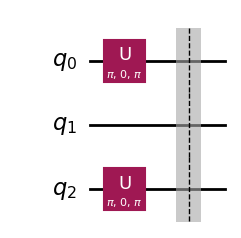

In [ ]:
def basis_encode(bit_string):
    """
    Encode a classical bit string into a quantum state using basis encoding.

    Args:
        bit_string: String of bits (e.g., '101') or list of bits (e.g., [1,0,1])

    Returns:
        QuantumCircuit that encodes the bit string
        QuantumCircuit is a class in Qiskit that represents a quantum circuit.
        Find the details at https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.QuantumCircuit
    """
    # Convert to list if string
    bits = [int(b) for b in bit_string if b in ('0', '1', 0, 1)]

    n_qubits = len(bits)
    qc = QuantumCircuit(n_qubits)

    # Apply X gate to qubits where bit is 1
    for i, bit in enumerate(bits):
        if bit == 1:
            qc.x(i)
    qc.barrier()
    return qc

#######################################################################################################################
#######################################################################################################################
# Example: Encode bit string '101' or specify your own bit string
bit_string = '101'
qc_basis = basis_encode(bit_string)
#######################################################################################################################
#######################################################################################################################

print(f"Encoding bit string: {bit_string}")
# Verify the statee
state = Statevector(qc_basis)
print(f"State vector: {state.data}")
# --- circuit visualization ---
qc_basis_decomposed = qc_basis.decompose()
qc_basis_decomposed.draw("mpl", fold=-1)


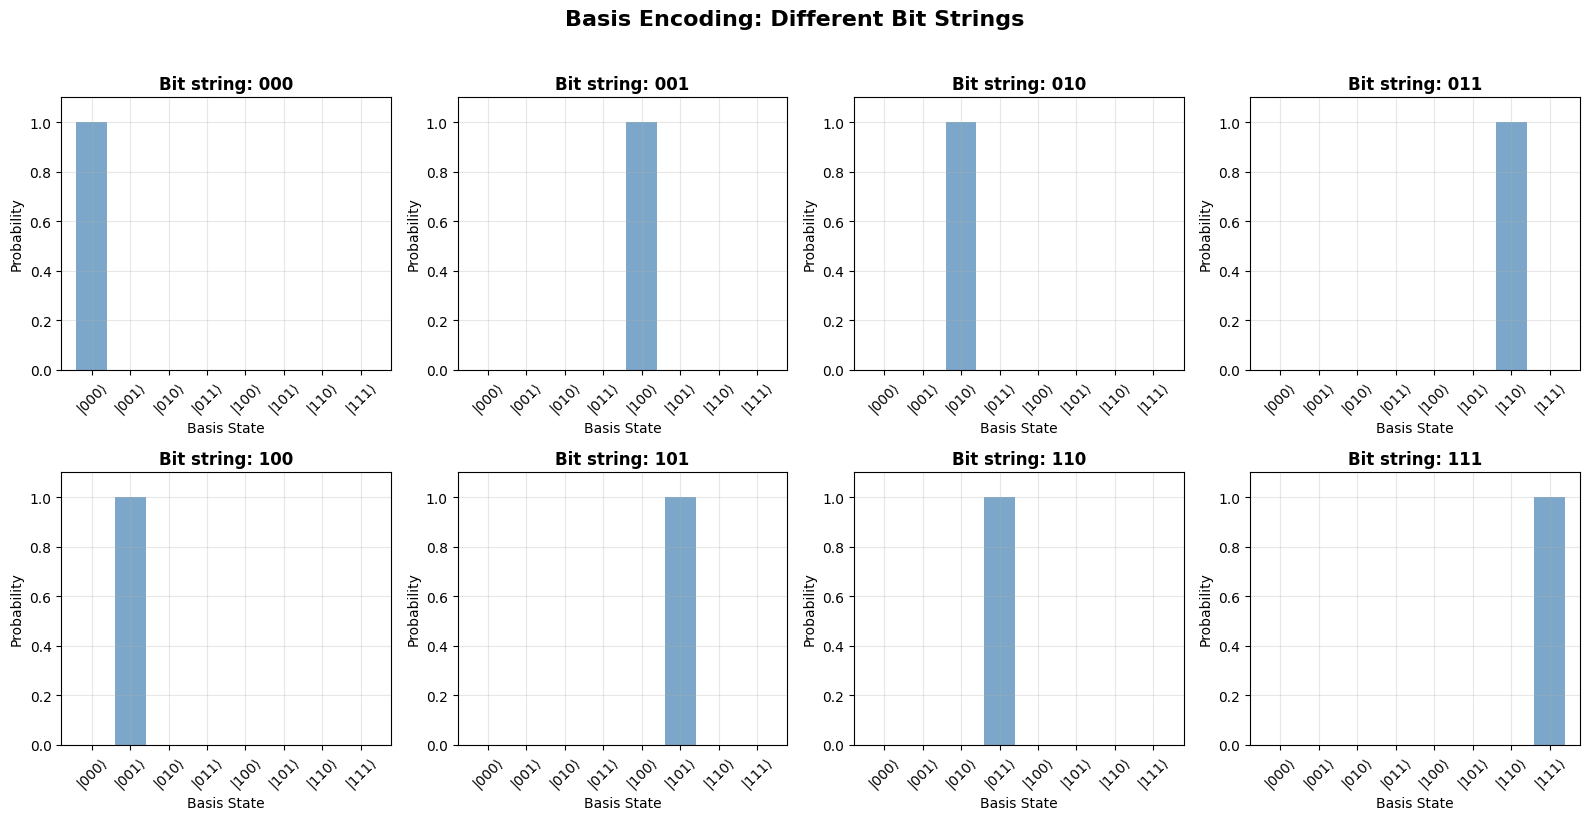

In [ ]:
# Visualize multiple bit strings
bit_strings = ['000', '001', '010', '011', '100', '101', '110', '111']

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for idx, bit_str in enumerate(bit_strings):
    qc = basis_encode(bit_str)
    state = Statevector(qc)

    # Get probability distribution
    probs = np.abs(state.data)**2

    # Plot bar chart
    axes[idx].bar(range(len(probs)), probs, color='steelblue', alpha=0.7)
    axes[idx].set_title(f'Bit string: {bit_str}', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('Basis State')
    axes[idx].set_ylabel('Probability')
    axes[idx].set_xticks(range(len(probs)))
    axes[idx].set_xticklabels([f'|{i:03b}⟩' for i in range(len(probs))], rotation=45)
    axes[idx].grid(True, alpha=0.3)
    axes[idx].set_ylim([0, 1.1])

plt.suptitle('Basis Encoding: Different Bit Strings', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 4. Amplitude Encoding

### Theory

**Amplitude encoding** encodes a classical data vector into the amplitudes of a quantum state. For a normalized vector $\mathbf{x} = (x_0, x_1, \ldots, x_{N-1})$ with $N = 2^n$:

$$|\psi\rangle = \sum_{i=0}^{N-1} x_i |i\rangle$$

where $|i\rangle$ are computational basis states and $\sum_i |x_i|^2 = 1$.

### Characteristics

- **Qubits needed**: $O(\log N)$ qubits for $N$-dimensional data (exponential compression!)
- **Circuit depth**: O($N$) - requires state preparation circuit
- **Advantages**:
  - Exponential compression (2^n amplitudes with n qubits)
  - Can encode dense information
  - Natural for quantum algorithms
- **Disadvantages**:
  - Requires normalization
  - State preparation can be complex
  - Difficult to read out individual amplitudes
  - Sensitive to noise

### Example

Encoding a 4-dimensional vector into 2 qubits.


In [ ]:
def amplitude_encode(data_vector):
    """
    Encode a classical data vector into quantum state amplitudes.

    Args:
        data_vector: 1D numpy array of data (will be normalized)

    Returns:
        QuantumCircuit that encodes the data
    """
    # Normalize the vector
    data = np.array(data_vector, dtype=complex)
    norm = np.linalg.norm(data)
    if norm == 0:
        raise ValueError("Cannot encode zero vector")
    normalized = data / norm

    # Number of qubits needed: log2(len(data))
    n_qubits = int(np.ceil(np.log2(len(normalized))))
    target_dim = 2**n_qubits

    # Pad with zeros if necessary
    if len(normalized) < target_dim:
        padded = np.zeros(target_dim, dtype=complex)
        padded[:len(normalized)] = normalized
        normalized = padded

    # Create quantum circuit
    qc = QuantumCircuit(n_qubits)

    # Use Qiskit's initialize method to prepare the state
    # This automatically creates the necessary gates
    qc.initialize(normalized, list(range(n_qubits)))

    return qc, normalized

#### Amplitude encoding prepares a quantum state starting from $\vert 0\rangle^{\otimes n}$.
#### It need not produce a fixed gate sequence.

Original data: [  1. 400.   3.   4.   5.  57.  61.]
Normalized data: [0.00244689+0.j 0.97875603+0.j 0.00734067+0.j 0.00978756+0.j
 0.01223445+0.j 0.13947273+0.j 0.14926029+0.j 0.        +0.j]

Encoded state amplitudes:
  |000⟩: 0.0024+0.0000j (probability: 0.0000)
  |001⟩: 0.9788+0.0000j (probability: 0.9580)
  |010⟩: 0.0073+0.0000j (probability: 0.0001)
  |011⟩: 0.0098+0.0000j (probability: 0.0001)
  |100⟩: 0.0122+0.0000j (probability: 0.0001)
  |101⟩: 0.1395+0.0000j (probability: 0.0195)
  |110⟩: 0.1493+0.0000j (probability: 0.0223)
  |111⟩: 0.0000+0.0000j (probability: 0.0000)

Circuit:


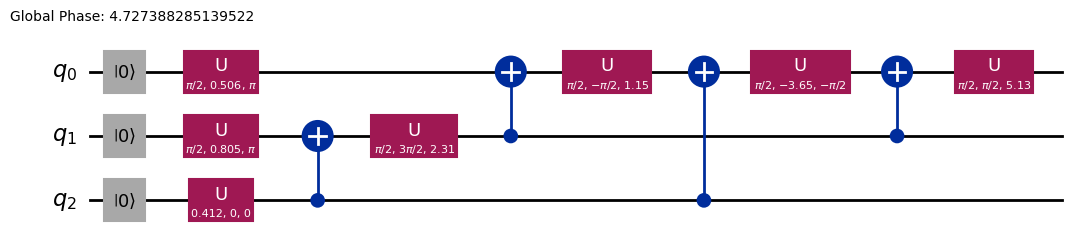

In [ ]:
# Example: Encode a 4-dimensional vector or specify your own data vector
#######################################################################################################################
#######################################################################################################################
data_vector = np.array([1.0, 400.0, 3.0, 4.0, 5.0, 57, 61])
l = len(data_vector)
#######################################################################################################################
#######################################################################################################################
qc_amplitude, normalized_data = amplitude_encode(data_vector)
print(f"Original data: {data_vector}")
print(f"Normalized data: {normalized_data}")

# Verify the state
state = Statevector(qc_amplitude)
print(f"\nEncoded state amplitudes:")
for i, amp in enumerate(state.data):
    print(f"  |{i:0{int(np.ceil(np.log2(l)))}b}⟩: {amp:.4f} (probability: {np.abs(amp)**2:.4f})")

print(f"\nCircuit:")
qc_decomposed = qc_amplitude.decompose(reps=10)
qc_decomposed.draw("mpl", fold=-1)

# fig = qc_amplitude.draw(
#     output="mpl",
#     style="iqp",
#     scale=1.3,
#     fold=-1,           ## single horizontal circuit
#     idle_wires=True    ## if set to false, it removes clutter from the circuit
# )
# plt.show()



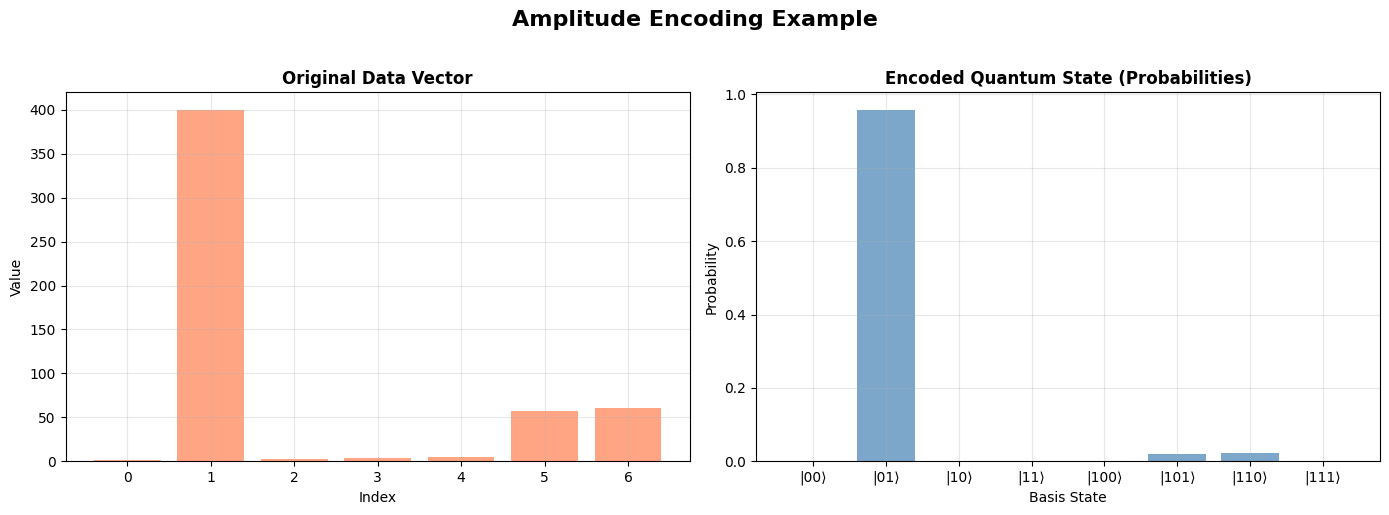


Compression: 7 values → 3 qubits
Information density: 7 / 8 = 87.50%


In [ ]:
# Visualize amplitude encoding
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Original data
axes[0].bar(range(len(data_vector)), data_vector, color='coral', alpha=0.7)
axes[0].set_title('Original Data Vector', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Index')
axes[0].set_ylabel('Value')
axes[0].grid(True, alpha=0.3)

# Encoded amplitudes
state = Statevector(qc_amplitude)
amplitudes = state.data
probabilities = np.abs(amplitudes)**2

x_pos = range(len(amplitudes))
axes[1].bar(x_pos, probabilities, color='steelblue', alpha=0.7)
axes[1].set_title('Encoded Quantum State (Probabilities)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Basis State')
axes[1].set_ylabel('Probability')
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels([f'|{i:02b}⟩' for i in x_pos])
axes[1].grid(True, alpha=0.3)

plt.suptitle('Amplitude Encoding Example', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print(f"\nCompression: {len(data_vector)} values → {qc_amplitude.num_qubits} qubits")
print(f"Information density: {len(data_vector)} / {2**qc_amplitude.num_qubits} = {len(data_vector) / 2**qc_amplitude.num_qubits:.2%}")


## 5. Angle Encoding

### Theory

**Angle encoding** (also called **rotation encoding**) encodes classical data into rotation angles of quantum gates. Each data feature is encoded as a rotation angle.

For a data vector $\mathbf{x} = (x_1, x_2, \ldots, x_n)$, we encode it as:

$$|\psi(\mathbf{x})\rangle = \bigotimes_{i=1}^{n} R_y(x_i) |0\rangle$$

or using different rotation axes:

$$|\psi(\mathbf{x})\rangle = \bigotimes_{i=1}^{n} R_z(x_i) |+\rangle$$

### Characteristics

- **Qubits needed**: $n$ qubits for $n$-dimensional data
- **Circuit depth**: O(1) - one layer of rotations
- **Advantages**:
  - Simple and hardware-efficient
  - Shallow circuits
  - Easy to implement
  - Good for continuous data
- **Disadvantages**:
  - Requires one qubit per feature
  - Limited expressiveness compared to amplitude encoding
  - May need multiple layers for complex data

### Variants

- **RY encoding**: $R_y(\theta)$ rotations on $|0\rangle$
- **RZ encoding**: $R_z(\theta)$ rotations on $|+\rangle$  
- **Multi-layer**: Multiple layers of rotations

### Example

Encoding a 3-dimensional vector using RY rotations.


In [ ]:
def angle_encode_ry(data_vector, scaling=1.0):
    """
    Encode a data vector using RY rotations (angle encoding).

    Args:
        data_vector: 1D numpy array of data
        scaling: Scaling factor for the angles (default: 1.0)

    Returns:
        QuantumCircuit that encodes the data
    """
    data = np.array(data_vector)
    n_qubits = len(data)

    qc = QuantumCircuit(n_qubits)

    # Apply RY rotation to each qubit
    for i, value in enumerate(data):
        qc.ry(scaling * value, i)
    qc.barrier()
    return qc

def angle_encode_rz(data_vector, scaling=1.0):
    """
    Encode a data vector using RZ rotations on |+> states.

    Args:
        data_vector: 1D numpy array of data
        scaling: Scaling factor for the angles (default: 1.0)

    Returns:
        QuantumCircuit that encodes the data
    """
    data = np.array(data_vector)
    n_qubits = len(data)

    qc = QuantumCircuit(n_qubits)

    # Initialize in |+> state (superposition)
    for i in range(n_qubits):
        qc.h(i)

    # Apply RZ rotation to each qubit
    for i, value in enumerate(data):
        qc.rz(scaling * value, i)
    qc.barrier()
    return qc

RY Angle Encoding:
Data: [0.5 4.5]

Encoded state amplitudes:
  |000⟩: -0.6086+0.0000j (probability: 0.3704)
  |001⟩: -0.1554+0.0000j (probability: 0.0242)
  |010⟩: 0.7539+0.0000j (probability: 0.5683)
  |011⟩: 0.1925+0.0000j (probability: 0.0371)

Circuit:


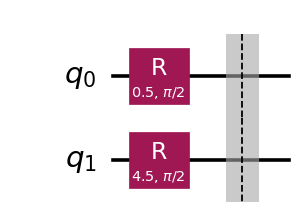

In [ ]:
# Example: Encode a 3-dimensional vector or specify your own data vector
#######################################################################################################################
#######################################################################################################################
data_vector = np.array([0.5, 4.5])
#######################################################################################################################
#######################################################################################################################

# RY encoding
qc_ry = angle_encode_ry(data_vector)
print("RY Angle Encoding:")
print(f"Data: {data_vector}")
# Verify the state
state = Statevector(qc_ry)
print(f"\nEncoded state amplitudes:")
for i, amp in enumerate(state.data):
    print(f"  |{i:0{int(np.ceil(np.log2(l)))}b}⟩: {amp:.4f} (probability: {np.abs(amp)**2:.4f})")

print(f"\nCircuit:")
qc_ry_decomposed = qc_ry.decompose()
qc_ry_decomposed.draw(output="mpl", style="iqp", scale=1.3, fold=-1, idle_wires=False)
# plt.show()



RZ Angle Encoding:

Encoded state amplitudes:
  |000⟩: -0.4006-0.2992j (probability: 0.2500)
  |001⟩: -0.2081-0.4546j (probability: 0.2500)
  |010⟩: -0.2081+0.4546j (probability: 0.2500)
  |011⟩: -0.4006+0.2992j (probability: 0.2500)

Circuit:


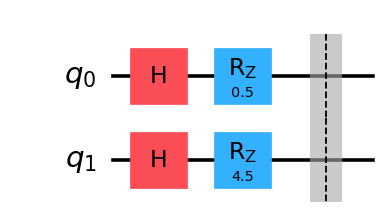

In [ ]:
# RZ encoding
qc_rz = angle_encode_rz(data_vector)
print(f"\n\nRZ Angle Encoding:")
state = Statevector(qc_rz)
print(f"\nEncoded state amplitudes:")
for i, amp in enumerate(state.data):
    print(f"  |{i:0{int(np.ceil(np.log2(l)))}b}⟩: {amp:.4f} (probability: {np.abs(amp)**2:.4f})")

print(f"\nCircuit:")
qc_rz.draw(
    output="mpl",
    style="iqp",
    scale=1.3,
    fold=-1,
    idle_wires=False
)

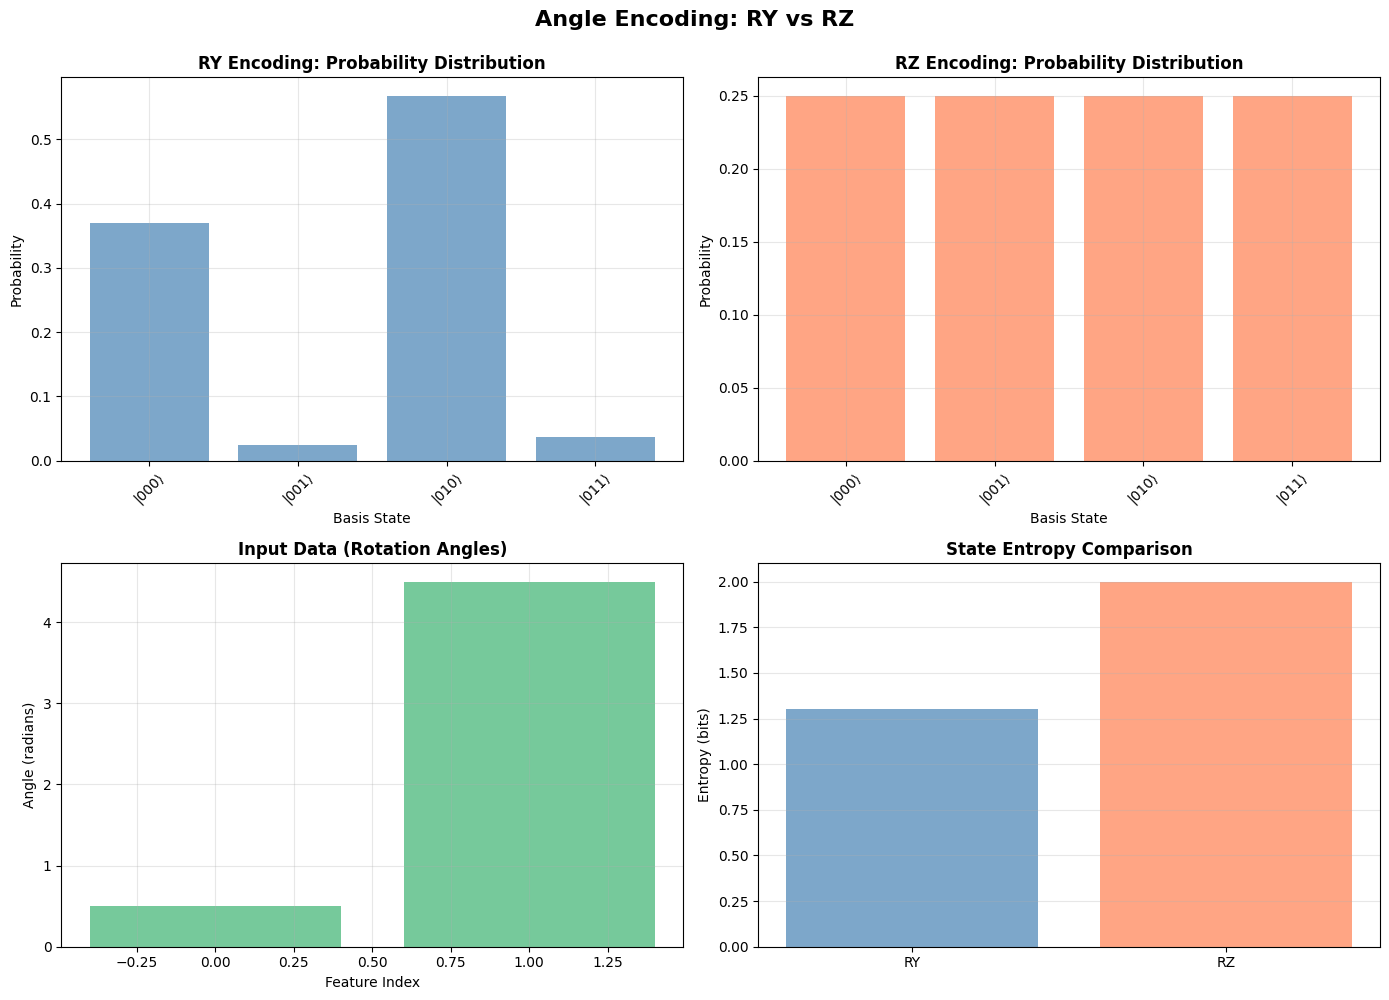

In [ ]:
# Visualize angle encoding
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# RY encoding state
state_ry = Statevector(qc_ry)
probs_ry = np.abs(state_ry.data)**2

axes[0, 0].bar(range(len(probs_ry)), probs_ry, color='steelblue', alpha=0.7)
axes[0, 0].set_title('RY Encoding: Probability Distribution', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Basis State')
axes[0, 0].set_ylabel('Probability')
axes[0, 0].set_xticks(range(len(probs_ry)))
axes[0, 0].set_xticklabels([f'|{i:03b}⟩' for i in range(len(probs_ry))], rotation=45)
axes[0, 0].grid(True, alpha=0.3)

# RZ encoding state
state_rz = Statevector(qc_rz)
probs_rz = np.abs(state_rz.data)**2

axes[0, 1].bar(range(len(probs_rz)), probs_rz, color='coral', alpha=0.7)
axes[0, 1].set_title('RZ Encoding: Probability Distribution', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Basis State')
axes[0, 1].set_ylabel('Probability')
axes[0, 1].set_xticks(range(len(probs_rz)))
axes[0, 1].set_xticklabels([f'|{i:03b}⟩' for i in range(len(probs_rz))], rotation=45)
axes[0, 1].grid(True, alpha=0.3)

# Compare angles
angles = data_vector
axes[1, 0].bar(range(len(angles)), angles, color='mediumseagreen', alpha=0.7)
axes[1, 0].set_title('Input Data (Rotation Angles)', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Feature Index')
axes[1, 0].set_ylabel('Angle (radians)')
axes[1, 0].grid(True, alpha=0.3)

# Bloch sphere visualization (for single qubit case)
if len(data_vector) == 1:
    # This would show Bloch sphere, but for multi-qubit we show comparison
    pass

# Comparison of encoding methods
methods = ['RY', 'RZ']
entropy_ry = -np.sum(probs_ry * np.log2(probs_ry + 1e-10))
entropy_rz = -np.sum(probs_rz * np.log2(probs_rz + 1e-10))
entropies = [entropy_ry, entropy_rz]

axes[1, 1].bar(methods, entropies, color=['steelblue', 'coral'], alpha=0.7)
axes[1, 1].set_title('State Entropy Comparison', fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel('Entropy (bits)')
axes[1, 1].grid(True, alpha=0.3, axis='y')

plt.suptitle('Angle Encoding: RY vs RZ', fontsize=16, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()


## 6. Qsample Encoding

### Theory

**Qsample encoding** encodes a probability distribution into a quantum state. Given a probability distribution $\mathbf{p} = (p_0, p_1, \ldots, p_{N-1})$ where $\sum_i p_i = 1$, we encode it as:

$$|\psi\rangle = \sum_{i=0}^{N-1} \sqrt{p_i} |i\rangle$$

This is similar to amplitude encoding, but specifically designed for probability distributions.

### Characteristics

- **Qubits needed**: $O(\log N)$ qubits for $N$-outcome distribution
- **Circuit depth**: O($N$) - requires state preparation
- **Advantages**:
  - Natural for probabilistic data
  - Can sample from distribution efficiently
  - Useful for quantum Monte Carlo methods
- **Disadvantages**:
  - Requires state preparation circuit
  - Similar limitations to amplitude encoding

### Example

Encoding a discrete probability distribution.


Original probabilities: [0.1  0.2  0.3  0.15 0.15 0.1 ]
Normalized probabilities: [0.1  0.2  0.3  0.15 0.15 0.1 ]
Sum: 1.000000

Encoded state (amplitudes):
  |000⟩: amplitude=0.3162+0.0000j, probability=0.1000, original=0.1000
  |001⟩: amplitude=0.4472+0.0000j, probability=0.2000, original=0.2000
  |010⟩: amplitude=0.5477+0.0000j, probability=0.3000, original=0.3000
  |011⟩: amplitude=0.3873+0.0000j, probability=0.1500, original=0.1500
  |100⟩: amplitude=0.3873+0.0000j, probability=0.1500, original=0.1500
  |101⟩: amplitude=0.3162+0.0000j, probability=0.1000, original=0.1000

Circuit:


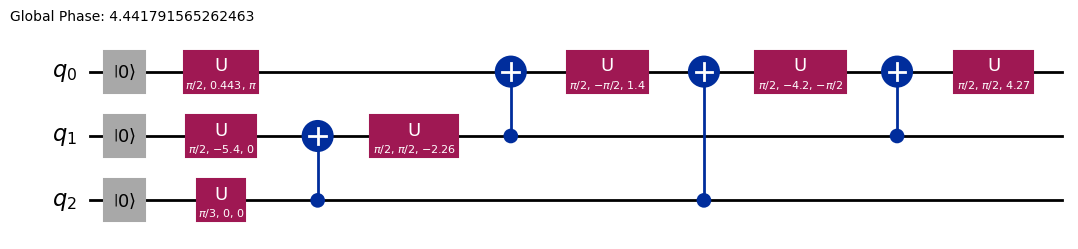

In [ ]:
def qsample_encode(probability_distribution):
    """
    Encode a probability distribution into a quantum state.

    Args:
        probability_distribution: 1D numpy array of probabilities (must sum to 1)

    Returns:
        QuantumCircuit that encodes the distribution
    """
    probs = np.array(probability_distribution)

    # Normalize to ensure it's a valid probability distribution
    probs = probs / np.sum(probs)

    # Convert probabilities to amplitudes (square root)
    amplitudes = np.sqrt(probs)

    # Number of qubits needed
    n_qubits = int(np.ceil(np.log2(len(amplitudes))))
    target_dim = 2**n_qubits

    # Pad with zeros if necessary
    if len(amplitudes) < target_dim:
        padded = np.zeros(target_dim, dtype=complex)
        padded[:len(amplitudes)] = amplitudes
        amplitudes = padded

    # Create quantum circuit
    qc = QuantumCircuit(n_qubits)
    qc.initialize(amplitudes, list(range(n_qubits)))

    return qc, probs

# Example: Encode a probability distribution
# Let's create a non-uniform distribution
prob_dist = np.array([0.1, 0.2, 0.3, 0.15, 0.15, 0.1])
qc_qsample, normalized_probs = qsample_encode(prob_dist)

print(f"Original probabilities: {prob_dist}")
print(f"Normalized probabilities: {normalized_probs}")
print(f"Sum: {np.sum(normalized_probs):.6f}")

# fig = qc_qsample.draw(
#     output="mpl",
#     style="iqp",
#     scale=1.3,
#     fold=-1,
#     idle_wires=False
# )
# plt.show()

# Verify the state
state = Statevector(qc_qsample)
print(f"\nEncoded state (amplitudes):")
for i in range(len(normalized_probs)):
    amp = state.data[i]
    prob = np.abs(amp)**2
    print(f"  |{i:03b}⟩: amplitude={amp:.4f}, probability={prob:.4f}, original={normalized_probs[i]:.4f}")

print(f"\nCircuit:")

qc_decomposed = qc_qsample.decompose(reps=10)
qc_decomposed.draw("mpl", fold=-1)

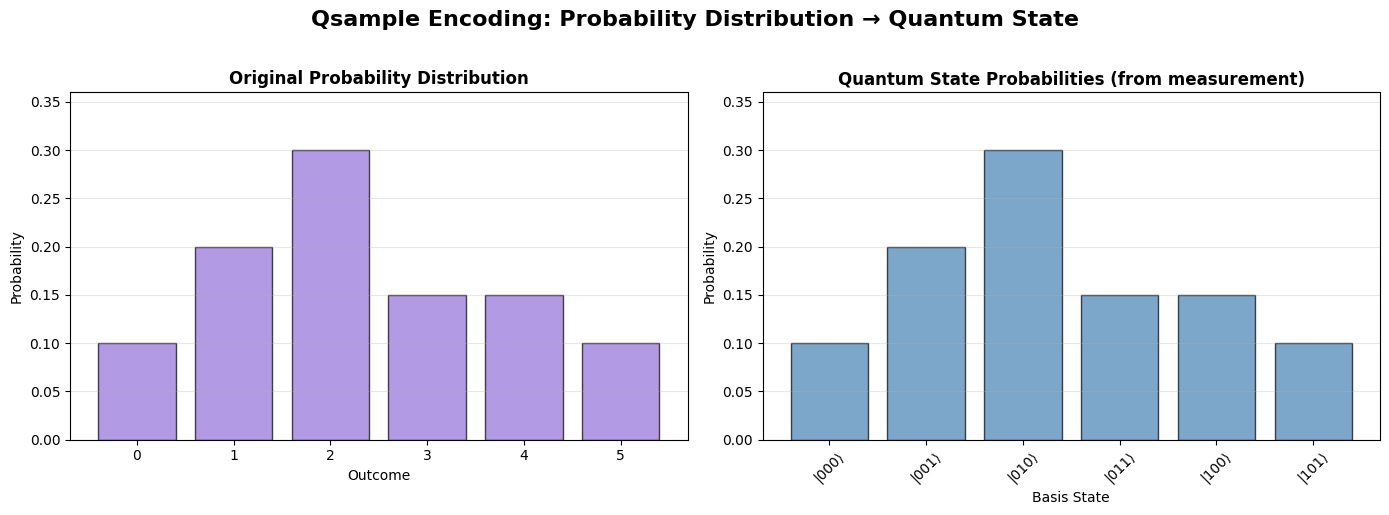


Sampling from quantum state:
Sample outcomes (1000 shots):
  000: 97 (9.70%)
  001: 210 (21.00%)
  010: 293 (29.30%)
  011: 151 (15.10%)
  100: 138 (13.80%)
  101: 111 (11.10%)


In [ ]:
# Visualize Qsample encoding
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Original probability distribution
x_pos = range(len(normalized_probs))
axes[0].bar(x_pos, normalized_probs, color='mediumpurple', alpha=0.7, edgecolor='black')
axes[0].set_title('Original Probability Distribution', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Outcome')
axes[0].set_ylabel('Probability')
axes[0].set_xticks(x_pos)
axes[0].grid(True, alpha=0.3, axis='y')
axes[0].set_ylim([0, max(normalized_probs) * 1.2])

# Encoded quantum state probabilities
state = Statevector(qc_qsample)
quantum_probs = np.abs(state.data)**2

axes[1].bar(x_pos, quantum_probs[:len(normalized_probs)], color='steelblue', alpha=0.7, edgecolor='black')
axes[1].set_title('Quantum State Probabilities (from measurement)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Basis State')
axes[1].set_ylabel('Probability')
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels([f'|{i:03b}⟩' for i in x_pos], rotation=45)
axes[1].grid(True, alpha=0.3, axis='y')
axes[1].set_ylim([0, max(quantum_probs) * 1.2])

plt.suptitle('Qsample Encoding: Probability Distribution → Quantum State', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Demonstrate sampling
print("\nSampling from quantum state:")
simulator = AerSimulator()
qc_measure = qc_qsample.copy()
qc_measure.measure_all()
job = simulator.run(qc_measure, shots=1000)
result = job.result()
counts = result.get_counts()

print(f"Sample outcomes (1000 shots):")
for state, count in sorted(counts.items()):
    print(f"  {state}: {count} ({count/1000:.2%})")


## 7. Hamiltonian Encoding

### Theory

**Hamiltonian encoding** encodes data into the parameters of a Hamiltonian operator. The data is used to construct a Hamiltonian $H(\mathbf{x})$ that acts on quantum states.

For data vector $\mathbf{x} = (x_1, x_2, \ldots, x_n)$, we construct:

$$H(\mathbf{x}) = \sum_{i=1}^{n} x_i H_i$$

where $H_i$ are fixed Hermitian operators (e.g., Pauli matrices).

### Characteristics

- **Qubits needed**: Depends on the Hamiltonian structure
- **Circuit depth**: O(poly n) - depends on Hamiltonian decomposition
- **Advantages**:
  - Natural for quantum simulation
  - Useful for time evolution: $e^{-iH(\mathbf{x})t}$
  - Can encode complex relationships
- **Disadvantages**:
  - More complex to implement
  - Requires Hamiltonian decomposition into gates
  - Deeper circuits typically needed

### Example

Encoding data into a linear combination of Pauli operators.


In [ ]:
from qiskit.quantum_info import Operator, SparsePauliOp
from qiskit.circuit import Parameter

def hamiltonian_encode(data_vector, n_qubits=None, pauli_basis='Z'):
    """
    Encode data into a Hamiltonian operator.

    Args:
        data_vector: 1D numpy array of data
        n_qubits: Number of qubits (default: len(data_vector))
        pauli_basis: Type of Pauli operators ('Z', 'X', 'Y', or 'mixed')

    Returns:
        SparsePauliOp representing the Hamiltonian
    """
    data = np.array(data_vector)

    if n_qubits is None:
        n_qubits = len(data)

    # Create Hamiltonian as sum of Pauli operators
    pauli_list = []
    coeffs = []

    if pauli_basis == 'Z':
        # H = sum_i x_i * Z_i
        for i, x in enumerate(data):
            if i < n_qubits:
                pauli_str = 'I' * i + 'Z' + 'I' * (n_qubits - i - 1)
                pauli_list.append(pauli_str)
                coeffs.append(x)
    elif pauli_basis == 'X':
        # H = sum_i x_i * X_i
        for i, x in enumerate(data):
            if i < n_qubits:
                pauli_str = 'I' * i + 'X' + 'I' * (n_qubits - i - 1)
                pauli_list.append(pauli_str)
                coeffs.append(x)
    elif pauli_basis == 'mixed':
        # Mix of X, Y, Z
        for i, x in enumerate(data):
            if i < n_qubits:
                if i % 3 == 0:
                    pauli_str = 'I' * i + 'X' + 'I' * (n_qubits - i - 1)
                elif i % 3 == 1:
                    pauli_str = 'I' * i + 'Y' + 'I' * (n_qubits - i - 1)
                else:
                    pauli_str = 'I' * i + 'Z' + 'I' * (n_qubits - i - 1)
                pauli_list.append(pauli_str)
                coeffs.append(x)

    # Create SparsePauliOp
    hamiltonian = SparsePauliOp(pauli_list, coeffs=coeffs)

    return hamiltonian

# Example: Encode data into Hamiltonian
data_vector = np.array([0.5, 1.0, 1.5])
hamiltonian = hamiltonian_encode(data_vector, pauli_basis='Z')

print(f"Data vector: {data_vector}")
print(f"\nHamiltonian:")
print(hamiltonian)
print(f"\nHamiltonian matrix:")
print(hamiltonian.to_matrix())


Data vector: [0.5 1.  1.5]

Hamiltonian:
SparsePauliOp(['ZII', 'IZI', 'IIZ'],
              coeffs=[0.5+0.j, 1. +0.j, 1.5+0.j])

Hamiltonian matrix:
[[ 3.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j]
 [ 0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j]
 [ 0.+0.j  0.+0.j  1.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j]
 [ 0.+0.j  0.+0.j  0.+0.j -2.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j]
 [ 0.+0.j  0.+0.j  0.+0.j  0.+0.j  2.+0.j  0.+0.j  0.+0.j  0.+0.j]
 [ 0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j -1.+0.j  0.+0.j  0.+0.j]
 [ 0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j]
 [ 0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j -3.+0.j]]


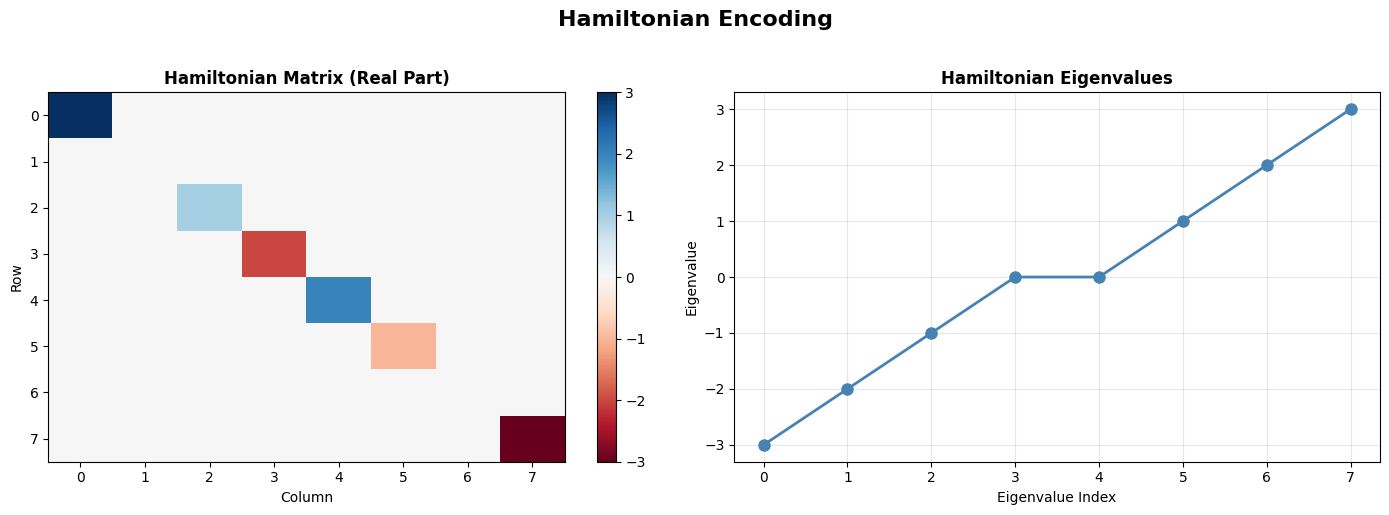


Time evolution: e^(-i*H*t)
Eigenvalues determine the evolution frequencies:
  λ_0 = -3.0000
  λ_1 = -2.0000
  λ_2 = -1.0000
  λ_3 = 0.0000
  λ_4 = 0.0000
  λ_5 = 1.0000
  λ_6 = 2.0000
  λ_7 = 3.0000


In [ ]:
# Visualize Hamiltonian encoding
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Show Hamiltonian structure
ham_matrix = hamiltonian.to_matrix()
im = axes[0].imshow(np.real(ham_matrix), cmap='RdBu', aspect='auto')
axes[0].set_title('Hamiltonian Matrix (Real Part)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Column')
axes[0].set_ylabel('Row')
plt.colorbar(im, ax=axes[0])

# Show eigenvalues
eigenvals = np.linalg.eigvalsh(ham_matrix)
axes[1].plot(eigenvals, 'o-', color='steelblue', markersize=8, linewidth=2)
axes[1].set_title('Hamiltonian Eigenvalues', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Eigenvalue Index')
axes[1].set_ylabel('Eigenvalue')
axes[1].grid(True, alpha=0.3)

plt.suptitle('Hamiltonian Encoding', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Demonstrate time evolution
print("\nTime evolution: e^(-i*H*t)")
print("Eigenvalues determine the evolution frequencies:")
for i, ev in enumerate(eigenvals):
    print(f"  λ_{i} = {ev:.4f}")


## 8. Quantum Feature Maps

### Theory

**Quantum Feature Maps** are structured encoding circuits designed specifically for quantum machine learning. They map classical data into quantum Hilbert space, creating a quantum feature space that can be used with quantum kernel methods or variational quantum classifiers.

Common feature maps include:

1. **ZZFeatureMap**: Uses $R_z$ rotations and $ZZ$ entangling gates
2. **PauliFeatureMap**: Uses Pauli rotations ($X$, $Y$, $Z$) with entangling gates
3. **Custom Feature Maps**: User-defined encoding circuits

### ZZFeatureMap

The ZZFeatureMap encodes data using:
- $R_z$ rotations parameterized by data features
- $ZZ$ entangling gates between qubits
- Repeats for multiple layers (reps)

For data vector $\mathbf{x} = (x_1, x_2, \ldots, x_n)$:

$$U_{\Phi(\mathbf{x})} = \prod_{d=1}^{D} \left[ \prod_{i=1}^{n} R_z(x_i) \prod_{i<j} ZZ(x_i x_j) \right]$$

where $D$ is the number of repetitions.

### PauliFeatureMap

The PauliFeatureMap uses Pauli rotations:
- $R_x$, $R_y$, $R_z$ rotations
- Entangling gates (e.g., $ZZ$, $YY$, $XX$)
- Configurable Pauli strings

### Example

Using ZZFeatureMap and PauliFeatureMap to encode data.


ZZFeatureMap:
Number of qubits: 3
Number of parameters: 3


ZZFeatureMap with data assigned:


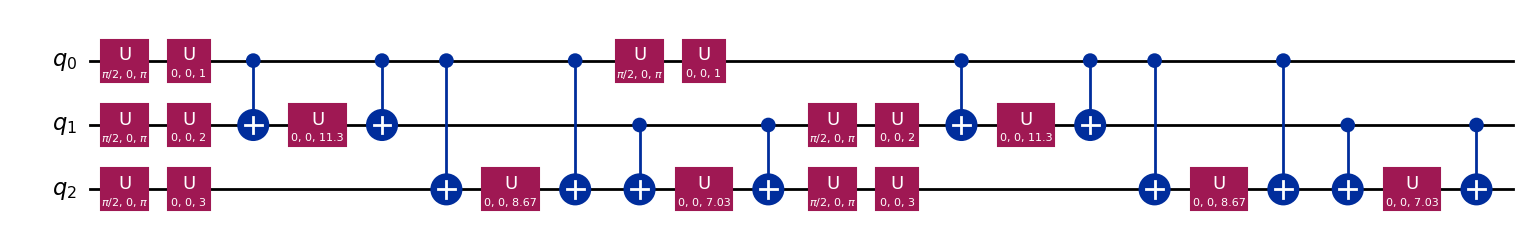

In [ ]:
# Example: Using ZZFeatureMap

# Create a 3-dimensional data vector
data_vector = np.array([0.5, 1.0, 1.5])
n_features = len(data_vector)

print("ZZFeatureMap:")
# Assign data to the feature map
zz_feature_map = ZZFeatureMap(feature_dimension=n_features, reps=2)
zz_circuit = zz_feature_map.assign_parameters(data_vector)
print(f"Number of qubits: {zz_feature_map.num_qubits}")
print(f"Number of parameters: {zz_feature_map.num_parameters}")
print(f"\n\nZZFeatureMap with data assigned:")
# Only decompose and draw once
zz_decomposed = zz_circuit.decompose(reps=2)
zz_decomposed.draw("mpl", fold=-1)

# # Draw the circuit with data assigned
# fig = zz_circuit.draw(
#     output="mpl",
#     style="iqp",
#     scale=1.3,
#     fold=-1
# )
# plt.show()


PauliFeatureMap:
Number of qubits: 3
Number of parameters: 3


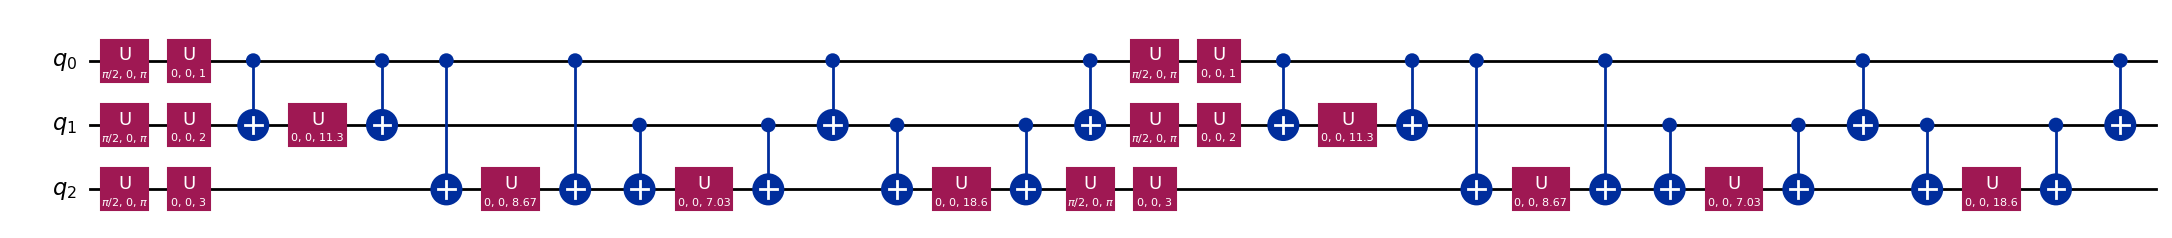

In [ ]:
# Example: Using PauliFeatureMap
# PauliFeatureMap with different Pauli strings
pauli_feature_map = PauliFeatureMap(feature_dimension=n_features, reps=2, paulis=['Z', 'ZZ', 'ZZZ'])
# Assign data
pauli_circuit = pauli_feature_map.assign_parameters(data_vector)
print("PauliFeatureMap:")
print(f"Number of qubits: {pauli_feature_map.num_qubits}")
print(f"Number of parameters: {pauli_feature_map.num_parameters}")
pauli_decomposed = pauli_circuit.decompose(reps=10)
pauli_decomposed.draw("mpl", fold=-1)
# plt.show()

# # Draw the circuit with data assigned
# fig = pauli_circuit.draw(
#     output="mpl",
#     style="iqp",
#     scale=1.3,
#     fold=-1
# )

### Characteristics

- **Qubits needed**: $n$ qubits for $n$-dimensional data
- **Circuit depth**: O($d \cdot n^2$) where $d$ is repetitions
- **Advantages**:
  - Designed for QML applications
  - Creates rich feature spaces
  - Entanglement captures correlations
  - Well-integrated with Qiskit ML tools
- **Disadvantages**:
  - Deeper circuits than simple angle encoding
  - More gates = more noise sensitivity
  - May require tuning of repetitions


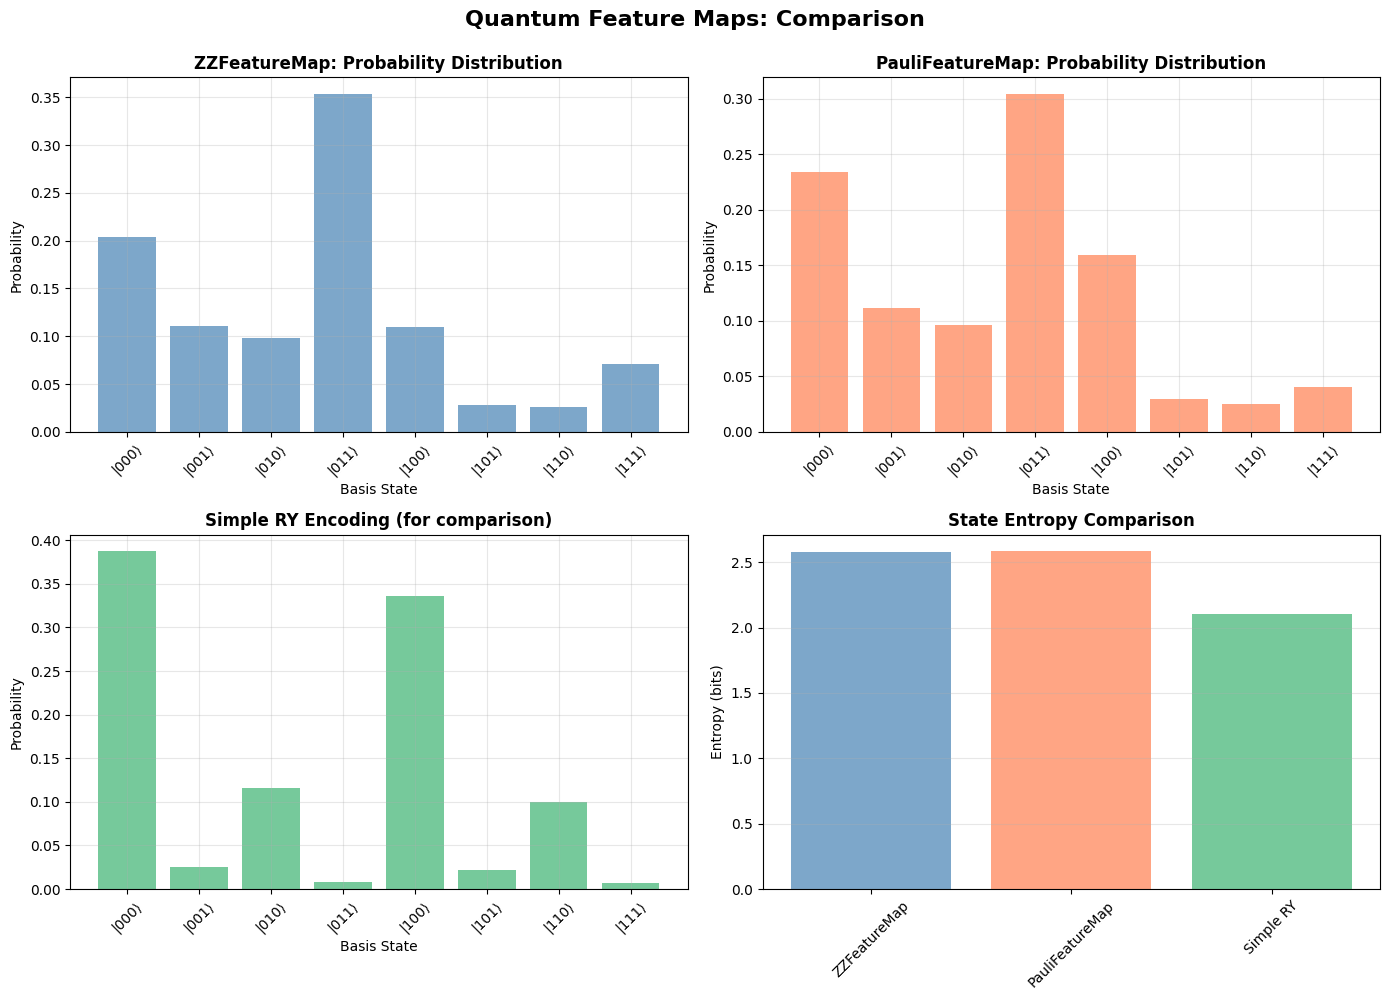


Circuit depths:
  ZZFeatureMap: 1 gates
  PauliFeatureMap: 1 gates
  Simple RY: 1 gates


In [ ]:
# Visualize feature maps
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# ZZFeatureMap state
state_zz = Statevector(zz_circuit)
probs_zz = np.abs(state_zz.data)**2

axes[0, 0].bar(range(len(probs_zz)), probs_zz, color='steelblue', alpha=0.7)
axes[0, 0].set_title('ZZFeatureMap: Probability Distribution', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Basis State')
axes[0, 0].set_ylabel('Probability')
axes[0, 0].set_xticks(range(len(probs_zz)))
axes[0, 0].set_xticklabels([f'|{i:03b}⟩' for i in range(len(probs_zz))], rotation=45)
axes[0, 0].grid(True, alpha=0.3)

# PauliFeatureMap state
state_pauli = Statevector(pauli_circuit)
probs_pauli = np.abs(state_pauli.data)**2

axes[0, 1].bar(range(len(probs_pauli)), probs_pauli, color='coral', alpha=0.7)
axes[0, 1].set_title('PauliFeatureMap: Probability Distribution', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Basis State')
axes[0, 1].set_ylabel('Probability')
axes[0, 1].set_xticks(range(len(probs_pauli)))
axes[0, 1].set_xticklabels([f'|{i:03b}⟩' for i in range(len(probs_pauli))], rotation=45)
axes[0, 1].grid(True, alpha=0.3)

# Compare with simple angle encoding
qc_ry_simple = angle_encode_ry(data_vector)
state_simple = Statevector(qc_ry_simple)
probs_simple = np.abs(state_simple.data)**2

axes[1, 0].bar(range(len(probs_simple)), probs_simple, color='mediumseagreen', alpha=0.7)
axes[1, 0].set_title('Simple RY Encoding (for comparison)', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Basis State')
axes[1, 0].set_ylabel('Probability')
axes[1, 0].set_xticks(range(len(probs_simple)))
axes[1, 0].set_xticklabels([f'|{i:03b}⟩' for i in range(len(probs_simple))], rotation=45)
axes[1, 0].grid(True, alpha=0.3)

# Compare entropies
entropy_zz = -np.sum(probs_zz * np.log2(probs_zz + 1e-10))
entropy_pauli = -np.sum(probs_pauli * np.log2(probs_pauli + 1e-10))
entropy_simple = -np.sum(probs_simple * np.log2(probs_simple + 1e-10))

methods = ['ZZFeatureMap', 'PauliFeatureMap', 'Simple RY']
entropies = [entropy_zz, entropy_pauli, entropy_simple]

axes[1, 1].bar(methods, entropies, color=['steelblue', 'coral', 'mediumseagreen'], alpha=0.7)
axes[1, 1].set_title('State Entropy Comparison', fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel('Entropy (bits)')
axes[1, 1].grid(True, alpha=0.3, axis='y')
axes[1, 1].tick_params(axis='x', rotation=45)

plt.suptitle('Quantum Feature Maps: Comparison', fontsize=16, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

print(f"\nCircuit depths:")
print(f"  ZZFeatureMap: {zz_circuit.depth()} gates")
print(f"  PauliFeatureMap: {pauli_circuit.depth()} gates")
print(f"  Simple RY: {qc_ry_simple.depth()} gates")


## 9. Real Dataset Application

Now let's apply the major encoding schemes to a real dataset. We'll use the **Iris dataset**, a classic machine learning dataset with 4 features and 3 classes.

We'll demonstrate:
1. **Angle Encoding** (RY) - Simple and hardware-efficient
2. **Amplitude Encoding** - Exponential compression
3. **ZZFeatureMap** - Designed for QML

### Dataset: Iris

The Iris dataset contains:
- 4 features: sepal length, sepal width, petal length, petal width
- 3 classes: Setosa, Versicolor, Virginica
- 150 samples total


In [ ]:
# Load Iris dataset
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler

iris = load_iris()
X, y = iris.data, iris.target

print(f"Iris dataset loaded:")
print(f"  Features: {X.shape[1]} (sepal length, sepal width, petal length, petal width)")
print(f"  Samples: {X.shape[0]}")
print(f"  Classes: {len(np.unique(y))} ({', '.join(iris.target_names)})")

# Normalize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Select a few samples for demonstration
sample_indices = [0, 50, 100]  # One from each class
samples = X_scaled[sample_indices]
sample_labels = y[sample_indices]

print(f"\nSelected samples (one from each class):")
for i, (sample, label) in enumerate(zip(samples, sample_labels)):
    print(f"  Sample {i+1} (Class: {iris.target_names[label]}): {sample}")


Iris dataset loaded:
  Features: 4 (sepal length, sepal width, petal length, petal width)
  Samples: 150
  Classes: 3 (setosa, versicolor, virginica)

Selected samples (one from each class):
  Sample 1 (Class: setosa): [-0.90068117  1.01900435 -1.34022653 -1.3154443 ]
  Sample 2 (Class: versicolor): [1.40150837 0.32841405 0.53540856 0.26414192]
  Sample 3 (Class: virginica): [0.55333328 0.55861082 1.27429511 1.71209594]


In [ ]:
# Encode samples using different schemes
iris_encodings = {}

for idx, sample in enumerate(samples):
    sample_name = f"Sample {idx+1} ({iris.target_names[sample_labels[idx]]})"
    iris_encodings[sample_name] = {}

    # 1. Angle Encoding (RY)
    qc_angle = angle_encode_ry(sample, scaling=np.pi/2)
    iris_encodings[sample_name]['Angle (RY)'] = qc_angle

    # 2. Amplitude Encoding
    # Pad to 8 dimensions (2^3) for 3 qubits
    padded_sample = np.pad(sample, (0, 4), mode='constant')
    qc_amp, _ = amplitude_encode(padded_sample)
    iris_encodings[sample_name]['Amplitude'] = qc_amp

    # 3. ZZFeatureMap
    zz_fm = ZZFeatureMap(feature_dimension=len(sample), reps=2)
    qc_zz = zz_fm.assign_parameters(sample)
    iris_encodings[sample_name]['ZZFeatureMap'] = qc_zz

print("Encoded samples using different schemes:")
for sample_name, encodings in iris_encodings.items():
    print(f"\n{sample_name}:")
    for enc_name, qc in encodings.items():
        print(f"  {enc_name}: {qc.num_qubits} qubits, depth {qc.depth()}")


Encoded samples using different schemes:

Sample 1 (setosa):
  Angle (RY): 4 qubits, depth 1
  Amplitude: 3 qubits, depth 1
  ZZFeatureMap: 4 qubits, depth 1

Sample 2 (versicolor):
  Angle (RY): 4 qubits, depth 1
  Amplitude: 3 qubits, depth 1
  ZZFeatureMap: 4 qubits, depth 1

Sample 3 (virginica):
  Angle (RY): 4 qubits, depth 1
  Amplitude: 3 qubits, depth 1
  ZZFeatureMap: 4 qubits, depth 1


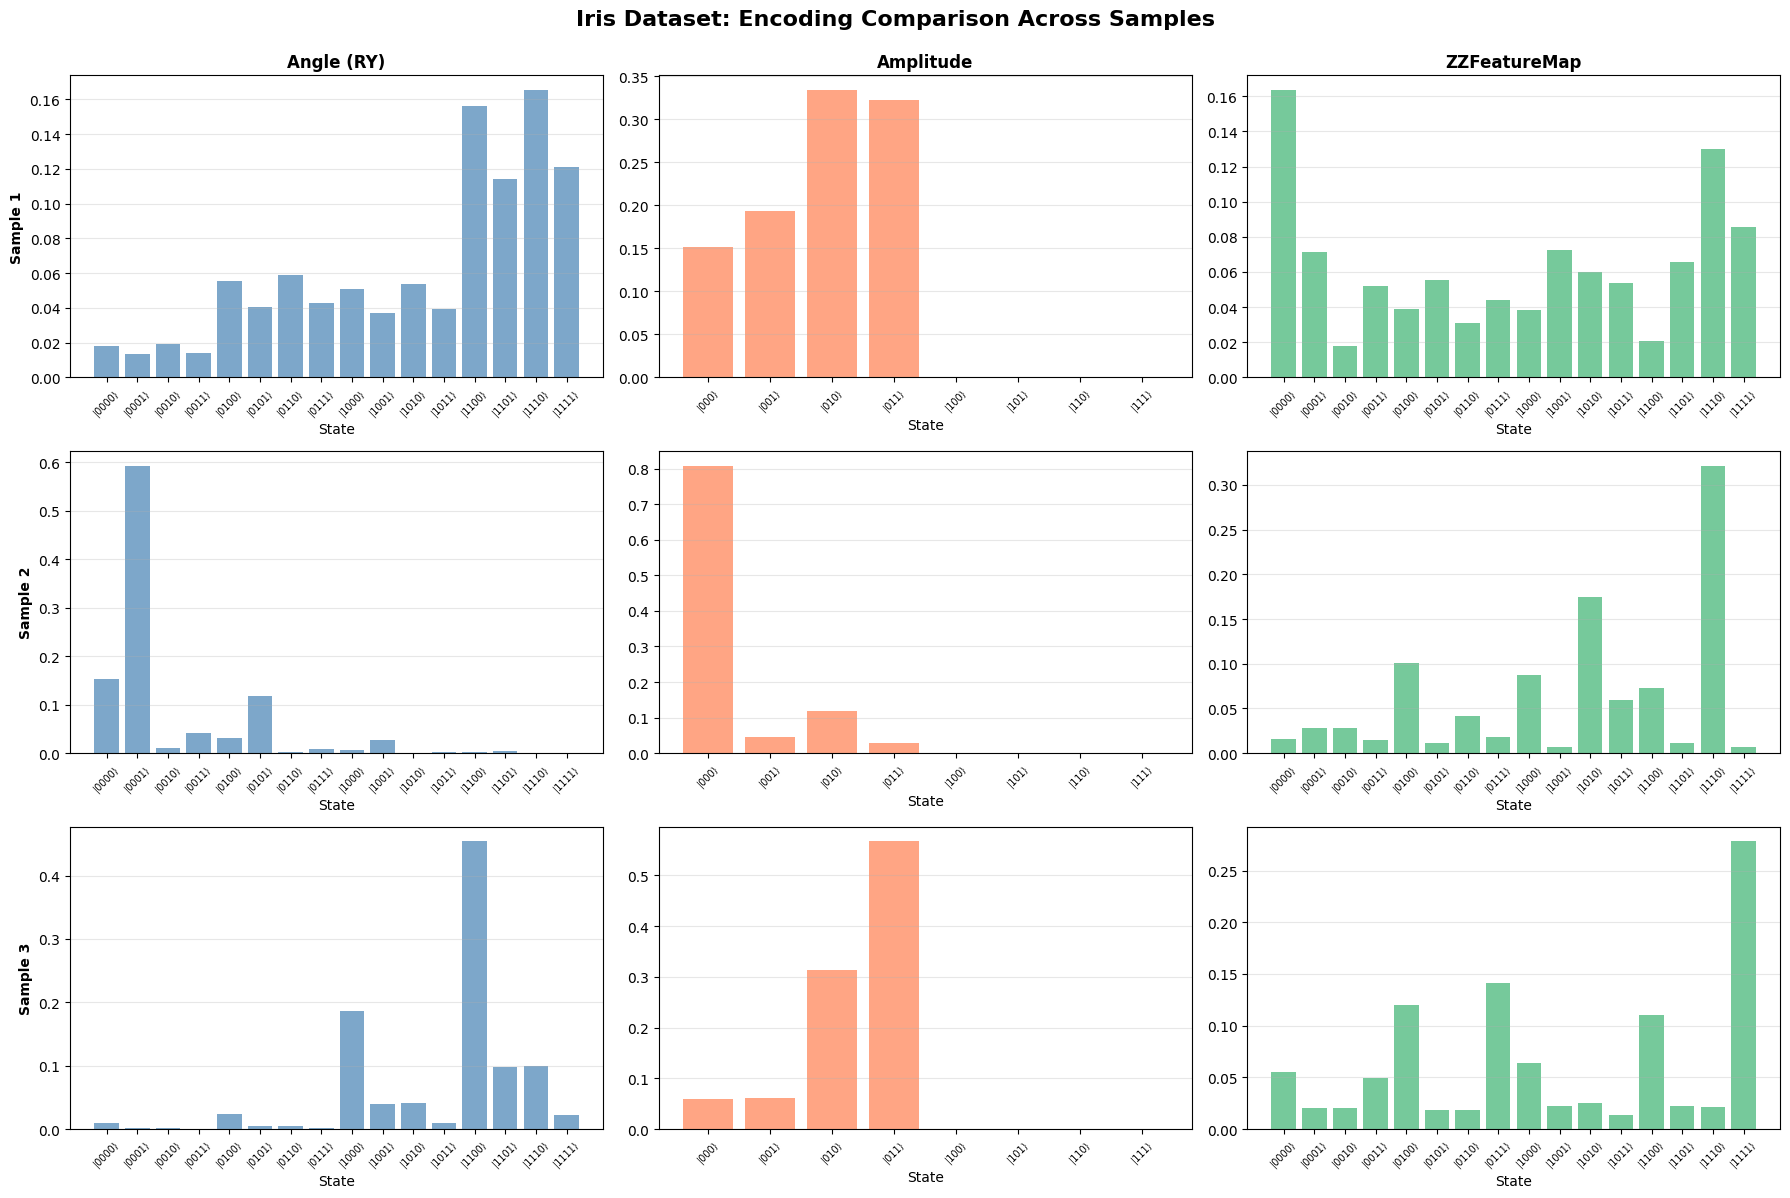

In [ ]:
# Visualize encodings for different samples
fig, axes = plt.subplots(3, 3, figsize=(18, 12))

for row, (sample_name, encodings) in enumerate(iris_encodings.items()):
    for col, (enc_name, qc) in enumerate(encodings.items()):
        state = Statevector(qc)
        probs = np.abs(state.data)**2

        # Show first 16 states for clarity
        n_show = min(16, len(probs))
        x_pos = range(n_show)

        axes[row, col].bar(x_pos, probs[:n_show], color=['steelblue', 'coral', 'mediumseagreen'][col],
                          alpha=0.7)
        if row == 0:
            axes[row, col].set_title(enc_name, fontsize=12, fontweight='bold')
        if col == 0:
            axes[row, col].set_ylabel(sample_name.split('(')[0].strip(), fontsize=10, fontweight='bold')

        axes[row, col].set_xlabel('State')
        axes[row, col].set_xticks(x_pos)
        if len(probs) <= 16:
            n_bits = int(np.ceil(np.log2(len(probs))))
            axes[row, col].set_xticklabels([f'|{i:0{n_bits}b}⟩' for i in x_pos],
                                         rotation=45, fontsize=7)
        else:
            axes[row, col].set_xticklabels([f'|{i:04b}⟩' for i in x_pos],
                                         rotation=45, fontsize=7)
        axes[row, col].grid(True, alpha=0.3, axis='y')

plt.suptitle('Iris Dataset: Encoding Comparison Across Samples',
             fontsize=16, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()


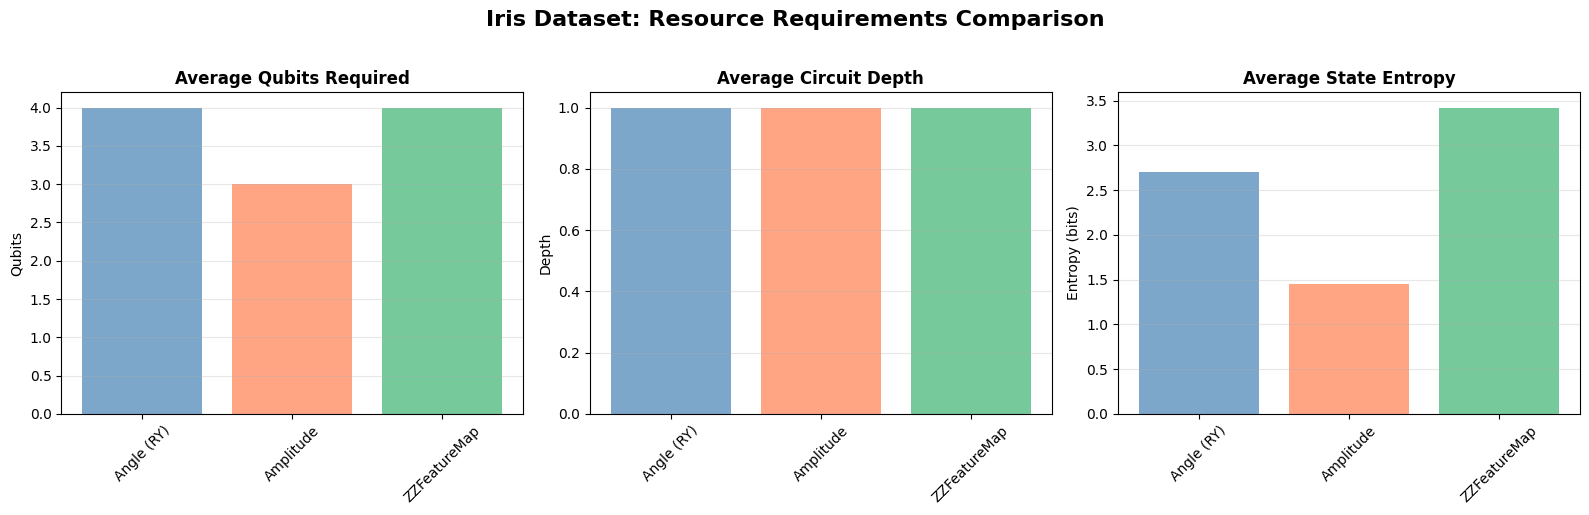


Summary for Iris dataset:
Encoding             Avg Qubits      Avg Depth       Avg Entropy    
-----------------------------------------------------------------
Angle (RY)           4.0             1.0             2.7038         
Amplitude            3.0             1.0             1.4526         
ZZFeatureMap         4.0             1.0             3.4210         


In [ ]:
# Compare resource requirements for Iris dataset
iris_comparison = {}

for sample_name, encodings in iris_encodings.items():
    for enc_name, qc in encodings.items():
        if enc_name not in iris_comparison:
            iris_comparison[enc_name] = {'qubits': [], 'depths': [], 'entropies': []}

        state = Statevector(qc)
        probs = np.abs(state.data)**2
        entropy = -np.sum(probs * np.log2(probs + 1e-10))

        iris_comparison[enc_name]['qubits'].append(qc.num_qubits)
        iris_comparison[enc_name]['depths'].append(qc.depth())
        iris_comparison[enc_name]['entropies'].append(entropy)

# Create comparison visualization
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

enc_names = list(iris_comparison.keys())
colors_bar = ['steelblue', 'coral', 'mediumseagreen']

# Average qubits
avg_qubits = [np.mean(iris_comparison[n]['qubits']) for n in enc_names]
axes[0].bar(enc_names, avg_qubits, color=colors_bar, alpha=0.7)
axes[0].set_title('Average Qubits Required', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Qubits')
axes[0].grid(True, alpha=0.3, axis='y')
axes[0].tick_params(axis='x', rotation=45)

# Average depth
avg_depths = [np.mean(iris_comparison[n]['depths']) for n in enc_names]
axes[1].bar(enc_names, avg_depths, color=colors_bar, alpha=0.7)
axes[1].set_title('Average Circuit Depth', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Depth')
axes[1].grid(True, alpha=0.3, axis='y')
axes[1].tick_params(axis='x', rotation=45)

# Average entropy
avg_entropies = [np.mean(iris_comparison[n]['entropies']) for n in enc_names]
axes[2].bar(enc_names, avg_entropies, color=colors_bar, alpha=0.7)
axes[2].set_title('Average State Entropy', fontsize=12, fontweight='bold')
axes[2].set_ylabel('Entropy (bits)')
axes[2].grid(True, alpha=0.3, axis='y')
axes[2].tick_params(axis='x', rotation=45)

plt.suptitle('Iris Dataset: Resource Requirements Comparison',
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("\nSummary for Iris dataset:")
print(f"{'Encoding':<20} {'Avg Qubits':<15} {'Avg Depth':<15} {'Avg Entropy':<15}")
print("-"*65)
for name in enc_names:
    print(f"{name:<20} {avg_qubits[enc_names.index(name)]:<15.1f} "
          f"{avg_depths[enc_names.index(name)]:<15.1f} "
          f"{avg_entropies[enc_names.index(name)]:<15.4f}")


## 10. Summary and Best Practices

### Summary of Encoding Schemes

| Encoding Scheme | Qubits | Depth | Pros | Cons | Best Use Case |
|----------------|--------|-------|------|------|---------------|
| **Basis Encoding** | O(n) | O(1) | Simple, direct mapping | One qubit per bit, binary only | Binary data, small datasets |
| **Amplitude Encoding** | O(log n) | O(n) | Exponential compression, dense info | Complex prep, noise sensitive | Large datasets, quantum algorithms |
| **Angle Encoding** | O(n) | O(1) | Simple, hardware-efficient, shallow | One qubit per feature | Continuous features, near-term hardware |
| **Qsample Encoding** | O(log n) | O(n) | Natural for probabilities | Complex prep | Probability distributions, Monte Carlo |
| **Hamiltonian Encoding** | O(n) | O(poly n) | Natural for simulation | Complex, deep circuits | Quantum simulation, time evolution |
| **Feature Maps** | O(n) | O(d·n²) | Rich feature space, QML-ready | Deeper circuits | Quantum ML, kernel methods |


### When to Choose Which Encoding

- **Small binary datasets** → Basis Encoding
- **Large dense datasets** → Amplitude Encoding  
- **Continuous features, shallow circuits needed** → Angle Encoding
- **Probability distributions** → Qsample Encoding
- **Quantum ML applications** → Feature Maps
- **Quantum simulation** → Hamiltonian Encoding

### Further Reading

- Schuld & Petruccione (2021): "Machine Learning with Quantum Computers" - Comprehensive QML textbook
- Havlíček et al. (2019): "Supervised learning with quantum-enhanced feature spaces" - Feature maps for QML
- Mitarai et al. (2018): "Quantum circuit learning" - Variational quantum circuits
- Biamonte et al. (2017): "Quantum machine learning" - Review paper

